# Importando Bibliotecas

In [1]:
import os

# Silencia avisos do Python (inclusive dos subprocessos do n_jobs=-1)
os.environ["PYTHONWARNINGS"] = "ignore"

import warnings

warnings.filterwarnings("ignore")
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

In [2]:
# Carregamento de dados
from joblib import load, dump

# Processamento de dados
import pandas as pd
import numpy as np

import os

# Estatística
from scipy.stats import chi2_contingency

# Graficos
import seaborn as sns
import matplotlib.pyplot as plt

# Classificador
import sys

sys.path.append("/home/sophia.ozorio/storage/python-ml/projeto_ML_python")

from dev.script.src.modelos.classifier import Classifier

# Importando Dados

In [3]:
# Pastas com o split 
caminho_dir = "/home/sophia.ozorio/storage/python-ml/projeto_ML_python/dev/script/results/split_dataset/"
caminho_res = "/home/sophia.ozorio/storage/python-ml/projeto_ML_python/dev/script/results/classificacao/"

# Verificando os arquivos no diretório do split
os.listdir(caminho_dir)

['y_ataxia_train_ready.csv',
 'df_valid_resultados_regression',
 'X_train_ready.csv',
 'y_idade_valid_ready.csv',
 'y_idade_test_ready.csv',
 'X_valid_ready.csv',
 'df_train_resultados_regression',
 'X_test_ready.csv',
 'y_ataxia_test_ready.csv',
 'df_test_resultados_regression',
 'y_ataxia_valid_ready.csv',
 'y_idade_train_ready.csv']

In [4]:
# Importando os dados de treino
X_train = pd.read_csv(f"{caminho_dir}X_train_ready.csv")
y_idade_train = pd.read_csv(f"{caminho_dir}y_idade_train_ready.csv")
y_ataxia_train = pd.read_csv(f"{caminho_dir}y_ataxia_train_ready.csv")

# Concatenando as features com a idade e o alvo (y_ataxia)
df_train = pd.concat([X_train, y_idade_train, y_ataxia_train], axis=1)

In [5]:
# Importando os dados de validação
X_valid = pd.read_csv(f"{caminho_dir}X_valid_ready.csv")
y_idade_valid = pd.read_csv(f"{caminho_dir}y_idade_valid_ready.csv") 
y_ataxia_valid = pd.read_csv(f"{caminho_dir}y_ataxia_valid_ready.csv")
df_valid = pd.concat([X_valid, y_idade_valid, y_ataxia_valid], axis=1)

In [6]:
# Importando os dados de teste
X_test = pd.read_csv(f"{caminho_dir}X_test_ready.csv")
y_idade_test = pd.read_csv(f"{caminho_dir}y_idade_test_ready.csv")   
y_ataxia_test = pd.read_csv(f"{caminho_dir}y_ataxia_test_ready.csv")
df_test = pd.concat([X_test, y_idade_test, y_ataxia_test], axis=1)

In [7]:
# Colunas originais (features + alvo)
colunas = df_train.columns.tolist()

# Validação cruzada e busca de hiperparâmetros

## Treino

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'knn__metric': 'manhattan', 'knn__n_neighbors': 51, 'knn__weights': 'uniform', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5679

--- Desempenho no Conjunto de Validação ---
Acurácia final: 0.5762



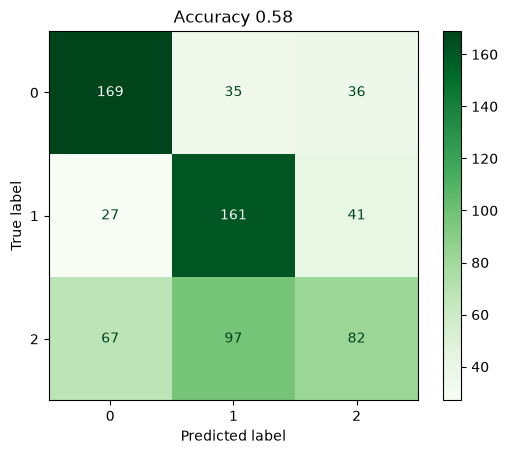


Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.70      0.67       240
           1       0.55      0.70      0.62       229
           2       0.52      0.33      0.40       246

    accuracy                           0.58       715
   macro avg       0.57      0.58      0.56       715
weighted avg       0.57      0.58      0.56       715

Total de variáveis originais pré-processadas: 23
Total de variáveis após VarianceThreshold:    23
Total de variáveis selecionadas no modelo:    23

--- Lista das Variáveis Selecionadas ---
1. tipo_variante_frameshift
2. tipo_variante_missense
3. tipo_variante_nonsense
4. ancestralidade_AFR
5. ancestralidade_AMR
6. ancestralidade_Desconhecido
7. ancestralidade_EAS
8. ancestralidade_EUR
9. ancestralidade_SAS
10. gene_HTT
11. gene_LRRK2
12. gene_PSEN1
13. gene_SOD1
14. classificacao_clinica_Benigna
15. classificacao_clinica_Patogenica
16. classificacao_clinica_VUS
17. cadd_phred
18. conserva

In [8]:
classificador = Classifier(df=df_train[colunas])

metricas_knn, pred_knn = classificador.classify(modelo="knn")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'linear', 'var_threshold__threshold': 0.05}
Melhor acurácia (CV): 0.5860

--- Desempenho no Conjunto de Validação ---
Acurácia final: 0.5986



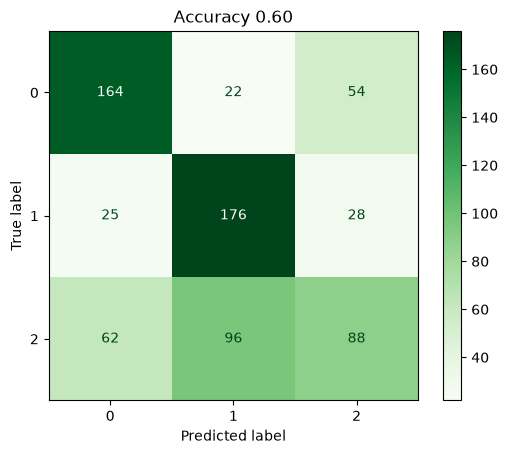


Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.68      0.67       240
           1       0.60      0.77      0.67       229
           2       0.52      0.36      0.42       246

    accuracy                           0.60       715
   macro avg       0.59      0.60      0.59       715
weighted avg       0.59      0.60      0.59       715

Total de variáveis originais pré-processadas: 23
Total de variáveis após VarianceThreshold:    23
Total de variáveis selecionadas no modelo:    23

--- Lista das Variáveis Selecionadas ---
1. tipo_variante_frameshift
2. tipo_variante_missense
3. tipo_variante_nonsense
4. ancestralidade_AFR
5. ancestralidade_AMR
6. ancestralidade_Desconhecido
7. ancestralidade_EAS
8. ancestralidade_EUR
9. ancestralidade_SAS
10. gene_HTT
11. gene_LRRK2
12. gene_PSEN1
13. gene_SOD1
14. classificacao_clinica_Benigna
15. classificacao_clinica_Patogenica
16. classificacao_clinica_VUS
17. cadd_phred
18. conserva

In [9]:
metricas_svm, pred_svm = classificador.classify(modelo="svm")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'rf__criterion': 'entropy', 'rf__max_depth': 5, 'rf__min_samples_split': 2, 'rf__n_estimators': 200, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5916

--- Desempenho no Conjunto de Validação ---
Acurácia final: 0.7063



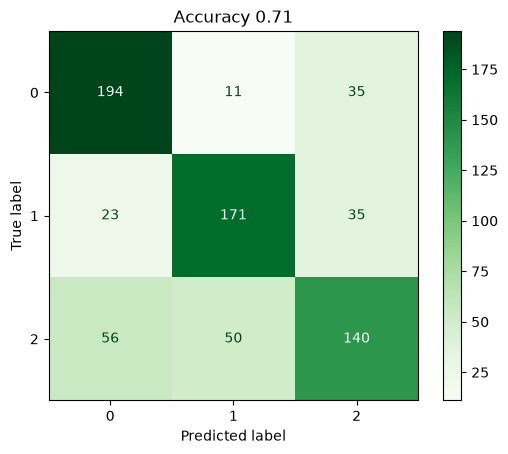


Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.81      0.76       240
           1       0.74      0.75      0.74       229
           2       0.67      0.57      0.61       246

    accuracy                           0.71       715
   macro avg       0.70      0.71      0.70       715
weighted avg       0.70      0.71      0.70       715

Total de variáveis originais pré-processadas: 23
Total de variáveis após VarianceThreshold:    23
Total de variáveis selecionadas no modelo:    23

--- Lista das Variáveis Selecionadas ---
1. tipo_variante_frameshift
2. tipo_variante_missense
3. tipo_variante_nonsense
4. ancestralidade_AFR
5. ancestralidade_AMR
6. ancestralidade_Desconhecido
7. ancestralidade_EAS
8. ancestralidade_EUR
9. ancestralidade_SAS
10. gene_HTT
11. gene_LRRK2
12. gene_PSEN1
13. gene_SOD1
14. classificacao_clinica_Benigna
15. classificacao_clinica_Patogenica
16. classificacao_clinica_VUS
17. cadd_phred
18. conserva

In [10]:
metricas_rf, pred_rf = classificador.classify(modelo="rf")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'gb__learning_rate': 0.01, 'gb__max_depth': 3, 'gb__n_estimators': 100, 'gb__subsample': 0.8, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5748

--- Desempenho no Conjunto de Validação ---
Acurácia final: 0.6867



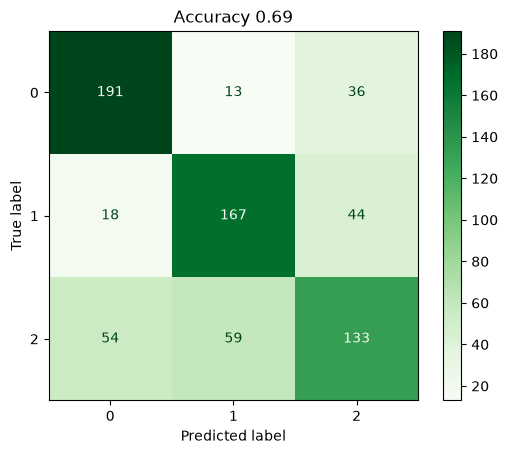


Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.80      0.76       240
           1       0.70      0.73      0.71       229
           2       0.62      0.54      0.58       246

    accuracy                           0.69       715
   macro avg       0.68      0.69      0.68       715
weighted avg       0.68      0.69      0.68       715

Total de variáveis originais pré-processadas: 23
Total de variáveis após VarianceThreshold:    23
Total de variáveis selecionadas no modelo:    23

--- Lista das Variáveis Selecionadas ---
1. tipo_variante_frameshift
2. tipo_variante_missense
3. tipo_variante_nonsense
4. ancestralidade_AFR
5. ancestralidade_AMR
6. ancestralidade_Desconhecido
7. ancestralidade_EAS
8. ancestralidade_EUR
9. ancestralidade_SAS
10. gene_HTT
11. gene_LRRK2
12. gene_PSEN1
13. gene_SOD1
14. classificacao_clinica_Benigna
15. classificacao_clinica_Patogenica
16. classificacao_clinica_VUS
17. cadd_phred
18. conserva

In [11]:
metricas_gbm, pred_gbm = classificador.classify(modelo="gbm")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'nb__var_smoothing': np.float64(0.001), 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5762

--- Desempenho no Conjunto de Validação ---
Acurácia final: 0.5846



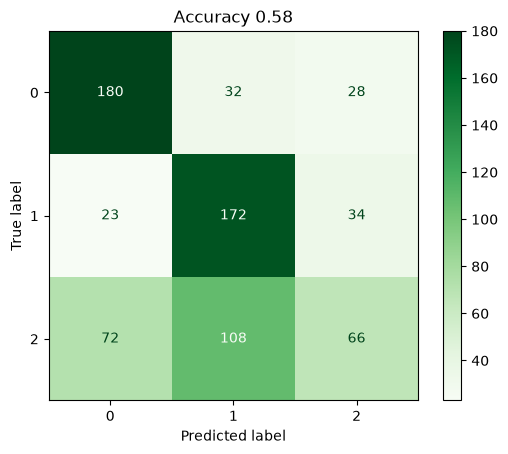


Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.75      0.70       240
           1       0.55      0.75      0.64       229
           2       0.52      0.27      0.35       246

    accuracy                           0.58       715
   macro avg       0.57      0.59      0.56       715
weighted avg       0.57      0.58      0.56       715

Total de variáveis originais pré-processadas: 23
Total de variáveis após VarianceThreshold:    23
Total de variáveis selecionadas no modelo:    23

--- Lista das Variáveis Selecionadas ---
1. tipo_variante_frameshift
2. tipo_variante_missense
3. tipo_variante_nonsense
4. ancestralidade_AFR
5. ancestralidade_AMR
6. ancestralidade_Desconhecido
7. ancestralidade_EAS
8. ancestralidade_EUR
9. ancestralidade_SAS
10. gene_HTT
11. gene_LRRK2
12. gene_PSEN1
13. gene_SOD1
14. classificacao_clinica_Benigna
15. classificacao_clinica_Patogenica
16. classificacao_clinica_VUS
17. cadd_phred
18. conserva

In [12]:
metricas_nb, pred_nb = classificador.classify(modelo="nb")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'mlp__activation': 'relu', 'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (20, 10), 'mlp__solver': 'adam', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5930

--- Desempenho no Conjunto de Validação ---
Acurácia final: 0.6378



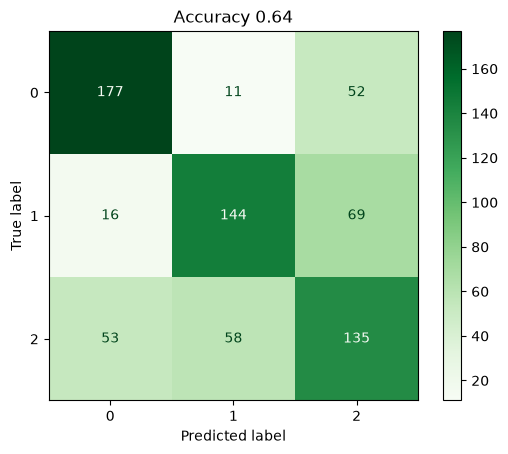


Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.74      0.73       240
           1       0.68      0.63      0.65       229
           2       0.53      0.55      0.54       246

    accuracy                           0.64       715
   macro avg       0.64      0.64      0.64       715
weighted avg       0.64      0.64      0.64       715

Total de variáveis originais pré-processadas: 23
Total de variáveis após VarianceThreshold:    23
Total de variáveis selecionadas no modelo:    23

--- Lista das Variáveis Selecionadas ---
1. tipo_variante_frameshift
2. tipo_variante_missense
3. tipo_variante_nonsense
4. ancestralidade_AFR
5. ancestralidade_AMR
6. ancestralidade_Desconhecido
7. ancestralidade_EAS
8. ancestralidade_EUR
9. ancestralidade_SAS
10. gene_HTT
11. gene_LRRK2
12. gene_PSEN1
13. gene_SOD1
14. classificacao_clinica_Benigna
15. classificacao_clinica_Patogenica
16. classificacao_clinica_VUS
17. cadd_phred
18. conserva

In [13]:
metricas_nn, pred_nn = classificador.classify(modelo="nn")

In [14]:
# Organizando as métricas de treinamento
df_metricas_train = pd.concat(
    [
        metricas_knn.T.copy(),
        metricas_svm.T.copy(),
        metricas_rf.T.copy(),
        metricas_gbm.T.copy(),
        metricas_nb.T.copy(),
        metricas_nn.T.copy(),
    ]
)
df_metricas_train.reset_index(inplace=True)
df_metricas_train["modelo"] = (
    ["k-NN"] * 4 + ["SVM"] * 4 + ["RF"] * 4 + ["GBM"] * 4 + ["NB"] * 4 + ["NN"] * 4
)
df_metricas_train.rename(columns={"index": "metricas", 0: "valores"}, inplace=True)
df_metricas_train.head()

,metricas,valores,modelo
0,Acurácia,0.5762,k-NN
1,Precision,0.5691,k-NN
2,Recall,0.5762,k-NN
3,F1-Score,0.5624,k-NN
4,Acurácia,0.5986,SVM


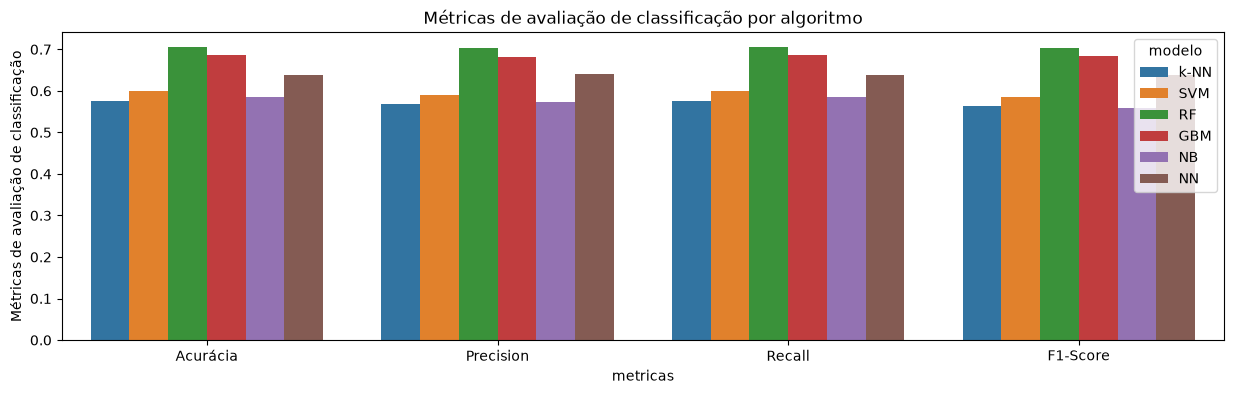

In [15]:
# Gráfico de barras das métricas de avaliação de classificação para os algoritmos
plt.figure(figsize=(15, 4))
plt.title("Métricas de avaliação de classificação por algoritmo")
p = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_train,
)
plt.ylabel("Métricas de avaliação de classificação")

plt.show()

In [16]:
df_train["k-NN"] = pred_knn.copy()
df_train["SVM"] = pred_svm.copy()
df_train["RF"] = pred_rf.copy()
df_train["GBM"] = pred_gbm.copy()
df_train["NB"] = pred_nb.copy()
df_train["NN"] = pred_nn.copy()
df_train.head()

,tipo_variante_frameshift,tipo_variante_missense,tipo_variante_nonsense,ancestralidade_AFR,ancestralidade_AMR,ancestralidade_Desconhecido,ancestralidade_EAS,ancestralidade_EUR,ancestralidade_SAS,gene_HTT,...,historico_familiar,gnomad_af_log,idade_inicio_sintomas,ataxia,k-NN,SVM,RF,GBM,NB,NN
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.346886,17.4,2,0,2,2,0,0,2
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.553847,36.0,1,2,2,2,2,1,2
2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,-0.275561,42.0,2,0,0,0,0,0,0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,-1.428356,24.8,2,0,0,0,0,0,0
4,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.685460,44.2,2,1,1,1,1,1,1


## Validação

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'knn__metric': 'manhattan', 'knn__n_neighbors': 51, 'knn__weights': 'uniform', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5679

--- Desempenho no Conjunto de Validação ---
Acurácia final: 0.6098



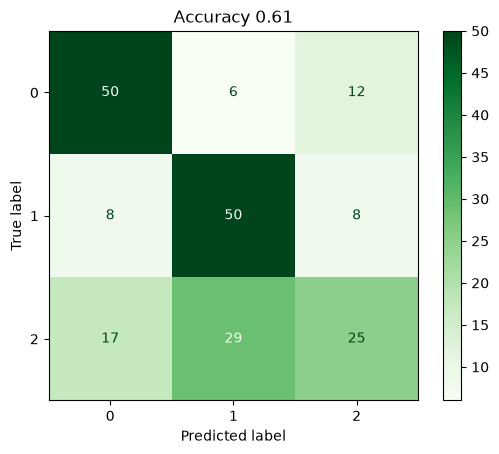


Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.74      0.70        68
           1       0.59      0.76      0.66        66
           2       0.56      0.35      0.43        71

    accuracy                           0.61       205
   macro avg       0.60      0.61      0.60       205
weighted avg       0.60      0.61      0.59       205

Total de variáveis originais pré-processadas: 23
Total de variáveis após VarianceThreshold:    23
Total de variáveis selecionadas no modelo:    23

--- Lista das Variáveis Selecionadas ---
1. tipo_variante_frameshift
2. tipo_variante_missense
3. tipo_variante_nonsense
4. ancestralidade_AFR
5. ancestralidade_AMR
6. ancestralidade_Desconhecido
7. ancestralidade_EAS
8. ancestralidade_EUR
9. ancestralidade_SAS
10. gene_HTT
11. gene_LRRK2
12. gene_PSEN1
13. gene_SOD1
14. classificacao_clinica_Benigna
15. classificacao_clinica_Patogenica
16. classificacao_clinica_VUS
17. cadd_phred
18. conserva

In [17]:
classificador = Classifier(df=df_train[colunas], df_val=df_valid[colunas])

metricas_knn, pred_knn = classificador.classify(modelo="knn")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'linear', 'var_threshold__threshold': 0.05}
Melhor acurácia (CV): 0.5860

--- Desempenho no Conjunto de Validação ---
Acurácia final: 0.5902



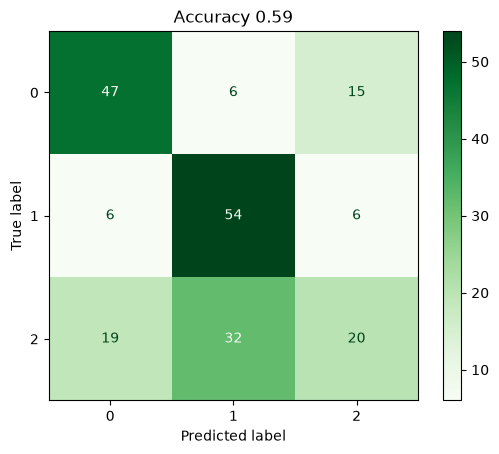


Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.69      0.67        68
           1       0.59      0.82      0.68        66
           2       0.49      0.28      0.36        71

    accuracy                           0.59       205
   macro avg       0.58      0.60      0.57       205
weighted avg       0.57      0.59      0.57       205

Total de variáveis originais pré-processadas: 23
Total de variáveis após VarianceThreshold:    23
Total de variáveis selecionadas no modelo:    23

--- Lista das Variáveis Selecionadas ---
1. tipo_variante_frameshift
2. tipo_variante_missense
3. tipo_variante_nonsense
4. ancestralidade_AFR
5. ancestralidade_AMR
6. ancestralidade_Desconhecido
7. ancestralidade_EAS
8. ancestralidade_EUR
9. ancestralidade_SAS
10. gene_HTT
11. gene_LRRK2
12. gene_PSEN1
13. gene_SOD1
14. classificacao_clinica_Benigna
15. classificacao_clinica_Patogenica
16. classificacao_clinica_VUS
17. cadd_phred
18. conserva

In [18]:
metricas_svm, pred_svm = classificador.classify(modelo="svm")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'rf__criterion': 'entropy', 'rf__max_depth': 5, 'rf__min_samples_split': 2, 'rf__n_estimators': 200, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5916

--- Desempenho no Conjunto de Validação ---
Acurácia final: 0.6244



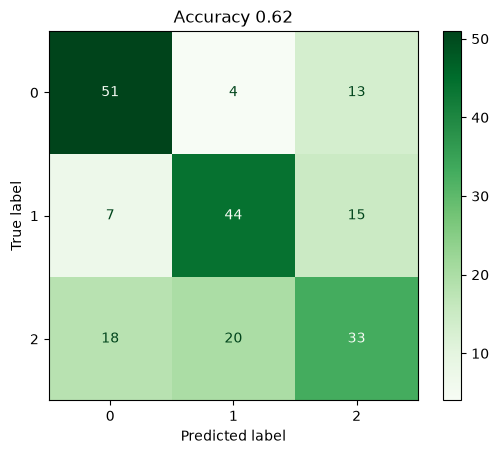


Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.75      0.71        68
           1       0.65      0.67      0.66        66
           2       0.54      0.46      0.50        71

    accuracy                           0.62       205
   macro avg       0.62      0.63      0.62       205
weighted avg       0.62      0.62      0.62       205

Total de variáveis originais pré-processadas: 23
Total de variáveis após VarianceThreshold:    23
Total de variáveis selecionadas no modelo:    23

--- Lista das Variáveis Selecionadas ---
1. tipo_variante_frameshift
2. tipo_variante_missense
3. tipo_variante_nonsense
4. ancestralidade_AFR
5. ancestralidade_AMR
6. ancestralidade_Desconhecido
7. ancestralidade_EAS
8. ancestralidade_EUR
9. ancestralidade_SAS
10. gene_HTT
11. gene_LRRK2
12. gene_PSEN1
13. gene_SOD1
14. classificacao_clinica_Benigna
15. classificacao_clinica_Patogenica
16. classificacao_clinica_VUS
17. cadd_phred
18. conserva

In [19]:
metricas_rf, pred_rf = classificador.classify(modelo="rf")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'gb__learning_rate': 0.01, 'gb__max_depth': 3, 'gb__n_estimators': 100, 'gb__subsample': 0.8, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5748

--- Desempenho no Conjunto de Validação ---
Acurácia final: 0.6341



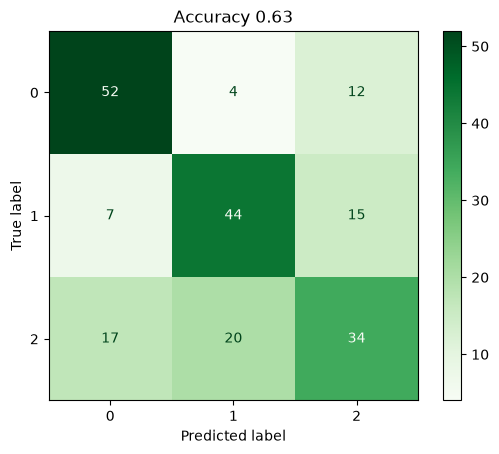


Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.76      0.72        68
           1       0.65      0.67      0.66        66
           2       0.56      0.48      0.52        71

    accuracy                           0.63       205
   macro avg       0.63      0.64      0.63       205
weighted avg       0.63      0.63      0.63       205

Total de variáveis originais pré-processadas: 23
Total de variáveis após VarianceThreshold:    23
Total de variáveis selecionadas no modelo:    23

--- Lista das Variáveis Selecionadas ---
1. tipo_variante_frameshift
2. tipo_variante_missense
3. tipo_variante_nonsense
4. ancestralidade_AFR
5. ancestralidade_AMR
6. ancestralidade_Desconhecido
7. ancestralidade_EAS
8. ancestralidade_EUR
9. ancestralidade_SAS
10. gene_HTT
11. gene_LRRK2
12. gene_PSEN1
13. gene_SOD1
14. classificacao_clinica_Benigna
15. classificacao_clinica_Patogenica
16. classificacao_clinica_VUS
17. cadd_phred
18. conserva

In [20]:
metricas_gbm, pred_gbm = classificador.classify(modelo="gbm")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'nb__var_smoothing': np.float64(0.001), 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5762

--- Desempenho no Conjunto de Validação ---
Acurácia final: 0.5707



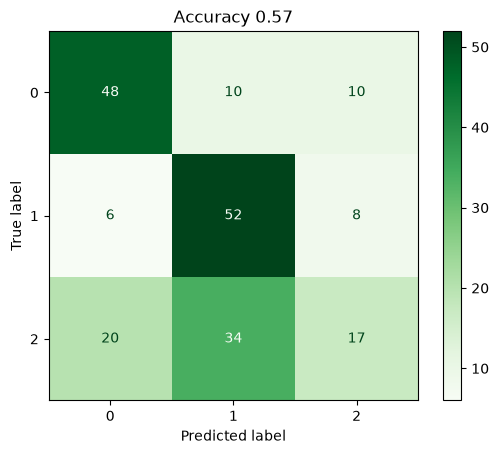


Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.71      0.68        68
           1       0.54      0.79      0.64        66
           2       0.49      0.24      0.32        71

    accuracy                           0.57       205
   macro avg       0.56      0.58      0.55       205
weighted avg       0.56      0.57      0.54       205

Total de variáveis originais pré-processadas: 23
Total de variáveis após VarianceThreshold:    23
Total de variáveis selecionadas no modelo:    23

--- Lista das Variáveis Selecionadas ---
1. tipo_variante_frameshift
2. tipo_variante_missense
3. tipo_variante_nonsense
4. ancestralidade_AFR
5. ancestralidade_AMR
6. ancestralidade_Desconhecido
7. ancestralidade_EAS
8. ancestralidade_EUR
9. ancestralidade_SAS
10. gene_HTT
11. gene_LRRK2
12. gene_PSEN1
13. gene_SOD1
14. classificacao_clinica_Benigna
15. classificacao_clinica_Patogenica
16. classificacao_clinica_VUS
17. cadd_phred
18. conserva

In [21]:
metricas_nb, pred_nb = classificador.classify(modelo="nb")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'mlp__activation': 'relu', 'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (20, 10), 'mlp__solver': 'adam', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5930

--- Desempenho no Conjunto de Validação ---
Acurácia final: 0.5854



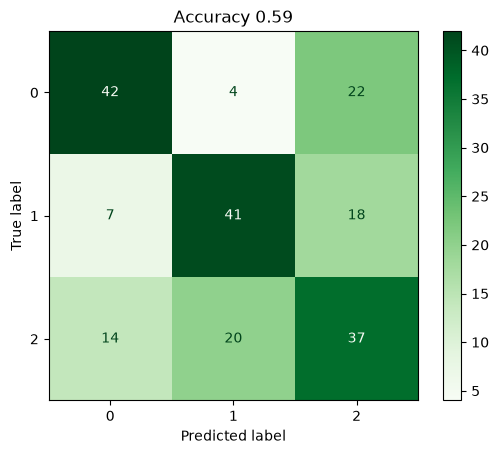


Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.62      0.64        68
           1       0.63      0.62      0.63        66
           2       0.48      0.52      0.50        71

    accuracy                           0.59       205
   macro avg       0.59      0.59      0.59       205
weighted avg       0.59      0.59      0.59       205

Total de variáveis originais pré-processadas: 23
Total de variáveis após VarianceThreshold:    23
Total de variáveis selecionadas no modelo:    23

--- Lista das Variáveis Selecionadas ---
1. tipo_variante_frameshift
2. tipo_variante_missense
3. tipo_variante_nonsense
4. ancestralidade_AFR
5. ancestralidade_AMR
6. ancestralidade_Desconhecido
7. ancestralidade_EAS
8. ancestralidade_EUR
9. ancestralidade_SAS
10. gene_HTT
11. gene_LRRK2
12. gene_PSEN1
13. gene_SOD1
14. classificacao_clinica_Benigna
15. classificacao_clinica_Patogenica
16. classificacao_clinica_VUS
17. cadd_phred
18. conserva

In [22]:
metricas_nn, pred_nn = classificador.classify(modelo="nn")

In [23]:
# Organizando as métricas de validação
df_metricas_valid = pd.concat(
    [
        metricas_knn.T.copy(),
        metricas_svm.T.copy(),
        metricas_rf.T.copy(),
        metricas_gbm.T.copy(),
        metricas_nb.T.copy(),
        metricas_nn.T.copy(),
    ]
)
df_metricas_valid.reset_index(inplace=True)
df_metricas_valid["modelo"] = (
    ["k-NN"] * 4 + ["SVM"] * 4 + ["RF"] * 4 + ["GBM"] * 4 + ["NB"] * 4 + ["NN"] * 4
)
df_metricas_valid.rename(columns={"index": "metricas", 0: "valores"}, inplace=True)
df_metricas_valid.head()

,metricas,valores,modelo
0,Acurácia,0.6098,k-NN
1,Precision,0.6029,k-NN
2,Recall,0.6098,k-NN
3,F1-Score,0.5945,k-NN
4,Acurácia,0.5902,SVM


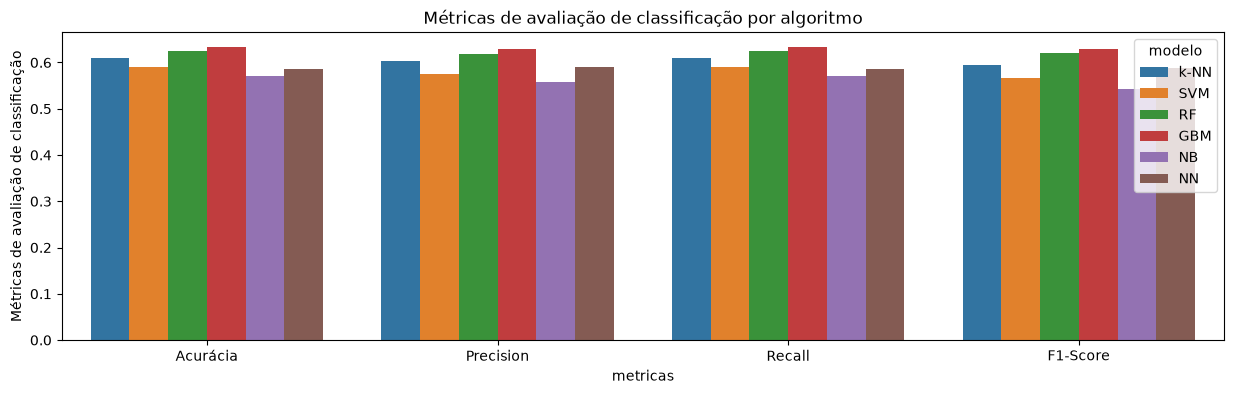

In [24]:
# Gráfico de barras das métricas de avaliação de classificação para os algoritmos
plt.figure(figsize=(15, 4))
plt.title("Métricas de avaliação de classificação por algoritmo")
p = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_valid,
)
plt.ylabel("Métricas de avaliação de classificação")

plt.show()

In [25]:
df_valid["k-NN"] = pred_knn.copy()
df_valid["SVM"] = pred_svm.copy()
df_valid["RF"] = pred_rf.copy()
df_valid["GBM"] = pred_gbm.copy()
df_valid["NB"] = pred_nb.copy()
df_valid["NN"] = pred_nn.copy()
df_valid.head()

,tipo_variante_frameshift,tipo_variante_missense,tipo_variante_nonsense,ancestralidade_AFR,ancestralidade_AMR,ancestralidade_Desconhecido,ancestralidade_EAS,ancestralidade_EUR,ancestralidade_SAS,gene_HTT,...,historico_familiar,gnomad_af_log,idade_inicio_sintomas,ataxia,k-NN,SVM,RF,GBM,NB,NN
0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,-1.428356,61.2,1,1,1,2,2,2,2
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.635265,45.1,1,1,1,1,1,1,1
2,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.174626,69.5,1,1,1,1,1,1,1
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,1.555511,34.9,2,2,2,2,2,1,2
4,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.043893,56.9,2,1,2,2,2,1,2


## Teste

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'knn__metric': 'manhattan', 'knn__n_neighbors': 51, 'knn__weights': 'uniform', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5679

--- Desempenho no Conjunto de Validação ---
Acurácia final: 0.5728



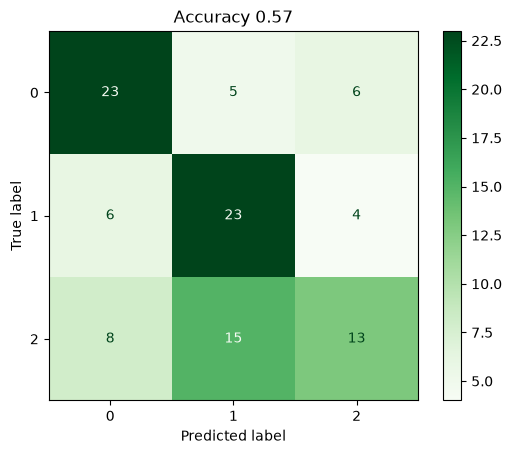


Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.68      0.65        34
           1       0.53      0.70      0.61        33
           2       0.57      0.36      0.44        36

    accuracy                           0.57       103
   macro avg       0.57      0.58      0.56       103
weighted avg       0.57      0.57      0.56       103

Total de variáveis originais pré-processadas: 23
Total de variáveis após VarianceThreshold:    23
Total de variáveis selecionadas no modelo:    23

--- Lista das Variáveis Selecionadas ---
1. tipo_variante_frameshift
2. tipo_variante_missense
3. tipo_variante_nonsense
4. ancestralidade_AFR
5. ancestralidade_AMR
6. ancestralidade_Desconhecido
7. ancestralidade_EAS
8. ancestralidade_EUR
9. ancestralidade_SAS
10. gene_HTT
11. gene_LRRK2
12. gene_PSEN1
13. gene_SOD1
14. classificacao_clinica_Benigna
15. classificacao_clinica_Patogenica
16. classificacao_clinica_VUS
17. cadd_phred
18. conserva

In [26]:
classificador = Classifier(df=df_train[colunas], df_val=df_test[colunas])

metricas_knn, pred_knn = classificador.classify(modelo="knn")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'linear', 'var_threshold__threshold': 0.05}
Melhor acurácia (CV): 0.5860

--- Desempenho no Conjunto de Validação ---
Acurácia final: 0.5534



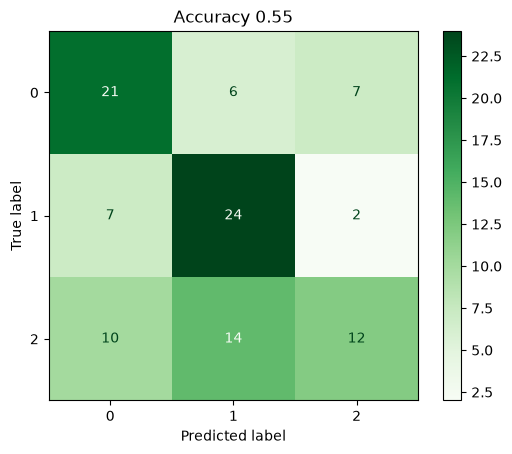


Classification Report:
              precision    recall  f1-score   support

           0       0.55      0.62      0.58        34
           1       0.55      0.73      0.62        33
           2       0.57      0.33      0.42        36

    accuracy                           0.55       103
   macro avg       0.56      0.56      0.54       103
weighted avg       0.56      0.55      0.54       103

Total de variáveis originais pré-processadas: 23
Total de variáveis após VarianceThreshold:    23
Total de variáveis selecionadas no modelo:    23

--- Lista das Variáveis Selecionadas ---
1. tipo_variante_frameshift
2. tipo_variante_missense
3. tipo_variante_nonsense
4. ancestralidade_AFR
5. ancestralidade_AMR
6. ancestralidade_Desconhecido
7. ancestralidade_EAS
8. ancestralidade_EUR
9. ancestralidade_SAS
10. gene_HTT
11. gene_LRRK2
12. gene_PSEN1
13. gene_SOD1
14. classificacao_clinica_Benigna
15. classificacao_clinica_Patogenica
16. classificacao_clinica_VUS
17. cadd_phred
18. conserva

In [27]:
metricas_svm, pred_svm = classificador.classify(modelo="svm")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'rf__criterion': 'entropy', 'rf__max_depth': 5, 'rf__min_samples_split': 2, 'rf__n_estimators': 200, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5916

--- Desempenho no Conjunto de Validação ---
Acurácia final: 0.6019



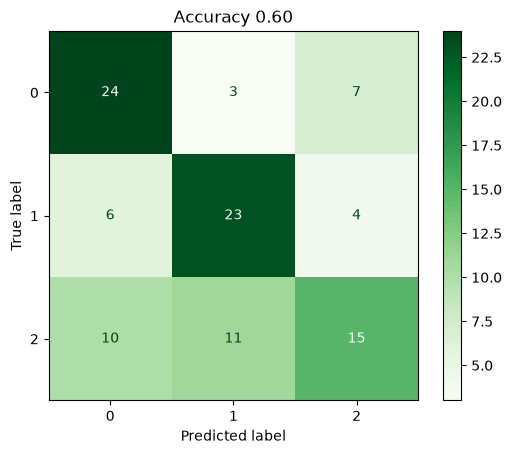


Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.71      0.65        34
           1       0.62      0.70      0.66        33
           2       0.58      0.42      0.48        36

    accuracy                           0.60       103
   macro avg       0.60      0.61      0.60       103
weighted avg       0.60      0.60      0.59       103

Total de variáveis originais pré-processadas: 23
Total de variáveis após VarianceThreshold:    23
Total de variáveis selecionadas no modelo:    23

--- Lista das Variáveis Selecionadas ---
1. tipo_variante_frameshift
2. tipo_variante_missense
3. tipo_variante_nonsense
4. ancestralidade_AFR
5. ancestralidade_AMR
6. ancestralidade_Desconhecido
7. ancestralidade_EAS
8. ancestralidade_EUR
9. ancestralidade_SAS
10. gene_HTT
11. gene_LRRK2
12. gene_PSEN1
13. gene_SOD1
14. classificacao_clinica_Benigna
15. classificacao_clinica_Patogenica
16. classificacao_clinica_VUS
17. cadd_phred
18. conserva

In [28]:
metricas_rf, pred_rf = classificador.classify(modelo="rf")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'gb__learning_rate': 0.01, 'gb__max_depth': 3, 'gb__n_estimators': 100, 'gb__subsample': 0.8, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5748

--- Desempenho no Conjunto de Validação ---
Acurácia final: 0.5631



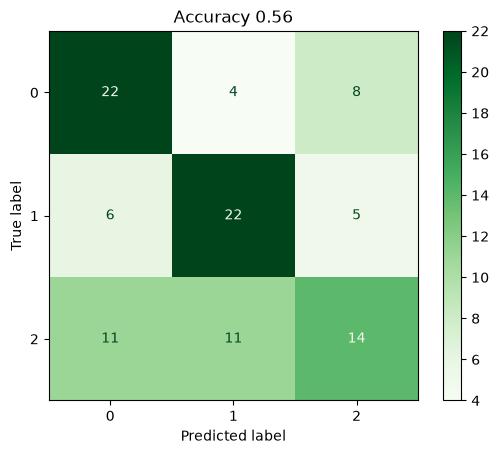


Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.65      0.60        34
           1       0.59      0.67      0.63        33
           2       0.52      0.39      0.44        36

    accuracy                           0.56       103
   macro avg       0.56      0.57      0.56       103
weighted avg       0.56      0.56      0.56       103

Total de variáveis originais pré-processadas: 23
Total de variáveis após VarianceThreshold:    23
Total de variáveis selecionadas no modelo:    23

--- Lista das Variáveis Selecionadas ---
1. tipo_variante_frameshift
2. tipo_variante_missense
3. tipo_variante_nonsense
4. ancestralidade_AFR
5. ancestralidade_AMR
6. ancestralidade_Desconhecido
7. ancestralidade_EAS
8. ancestralidade_EUR
9. ancestralidade_SAS
10. gene_HTT
11. gene_LRRK2
12. gene_PSEN1
13. gene_SOD1
14. classificacao_clinica_Benigna
15. classificacao_clinica_Patogenica
16. classificacao_clinica_VUS
17. cadd_phred
18. conserva

In [29]:
metricas_gbm, pred_gbm = classificador.classify(modelo="gbm")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'nb__var_smoothing': np.float64(0.001), 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5762

--- Desempenho no Conjunto de Validação ---
Acurácia final: 0.5340



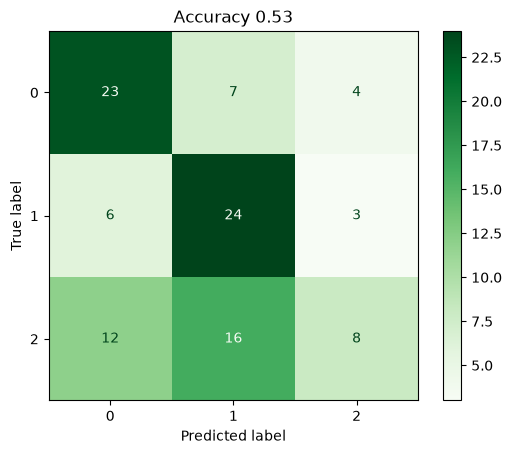


Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.68      0.61        34
           1       0.51      0.73      0.60        33
           2       0.53      0.22      0.31        36

    accuracy                           0.53       103
   macro avg       0.53      0.54      0.51       103
weighted avg       0.54      0.53      0.50       103

Total de variáveis originais pré-processadas: 23
Total de variáveis após VarianceThreshold:    23
Total de variáveis selecionadas no modelo:    23

--- Lista das Variáveis Selecionadas ---
1. tipo_variante_frameshift
2. tipo_variante_missense
3. tipo_variante_nonsense
4. ancestralidade_AFR
5. ancestralidade_AMR
6. ancestralidade_Desconhecido
7. ancestralidade_EAS
8. ancestralidade_EUR
9. ancestralidade_SAS
10. gene_HTT
11. gene_LRRK2
12. gene_PSEN1
13. gene_SOD1
14. classificacao_clinica_Benigna
15. classificacao_clinica_Patogenica
16. classificacao_clinica_VUS
17. cadd_phred
18. conserva

In [30]:
metricas_nb, pred_nb = classificador.classify(modelo="nb")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'mlp__activation': 'relu', 'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (20, 10), 'mlp__solver': 'adam', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5930

--- Desempenho no Conjunto de Validação ---
Acurácia final: 0.5534



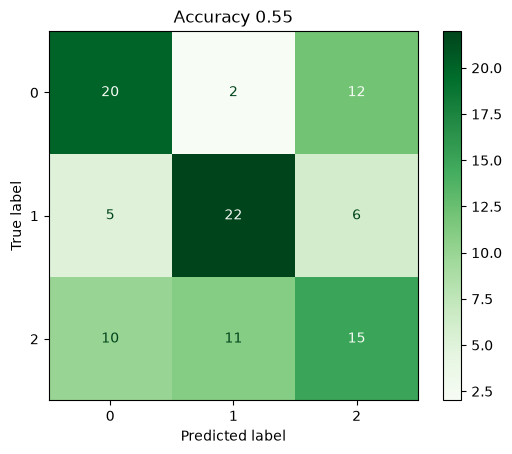


Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.59      0.58        34
           1       0.63      0.67      0.65        33
           2       0.45      0.42      0.43        36

    accuracy                           0.55       103
   macro avg       0.55      0.56      0.55       103
weighted avg       0.55      0.55      0.55       103

Total de variáveis originais pré-processadas: 23
Total de variáveis após VarianceThreshold:    23
Total de variáveis selecionadas no modelo:    23

--- Lista das Variáveis Selecionadas ---
1. tipo_variante_frameshift
2. tipo_variante_missense
3. tipo_variante_nonsense
4. ancestralidade_AFR
5. ancestralidade_AMR
6. ancestralidade_Desconhecido
7. ancestralidade_EAS
8. ancestralidade_EUR
9. ancestralidade_SAS
10. gene_HTT
11. gene_LRRK2
12. gene_PSEN1
13. gene_SOD1
14. classificacao_clinica_Benigna
15. classificacao_clinica_Patogenica
16. classificacao_clinica_VUS
17. cadd_phred
18. conserva

In [31]:
metricas_nn, pred_nn = classificador.classify(modelo="nn")

In [32]:
# Organizando as métricas de teste
df_metricas_test = pd.concat(
    [
        metricas_knn.T.copy(),
        metricas_svm.T.copy(),
        metricas_rf.T.copy(),
        metricas_gbm.T.copy(),
        metricas_nb.T.copy(),
        metricas_nn.T.copy(),
    ]
)
df_metricas_test.reset_index(inplace=True)
df_metricas_test["modelo"] = (
    ["k-NN"] * 4 + ["SVM"] * 4 + ["RF"] * 4 + ["GBM"] * 4 + ["NB"] * 4 + ["NN"] * 4
)
df_metricas_test.rename(columns={"index": "metricas", 0: "valores"}, inplace=True)
df_metricas_test.head()

,metricas,valores,modelo
0,Acurácia,0.5728,k-NN
1,Precision,0.5741,k-NN
2,Recall,0.5728,k-NN
3,F1-Score,0.5618,k-NN
4,Acurácia,0.5534,SVM


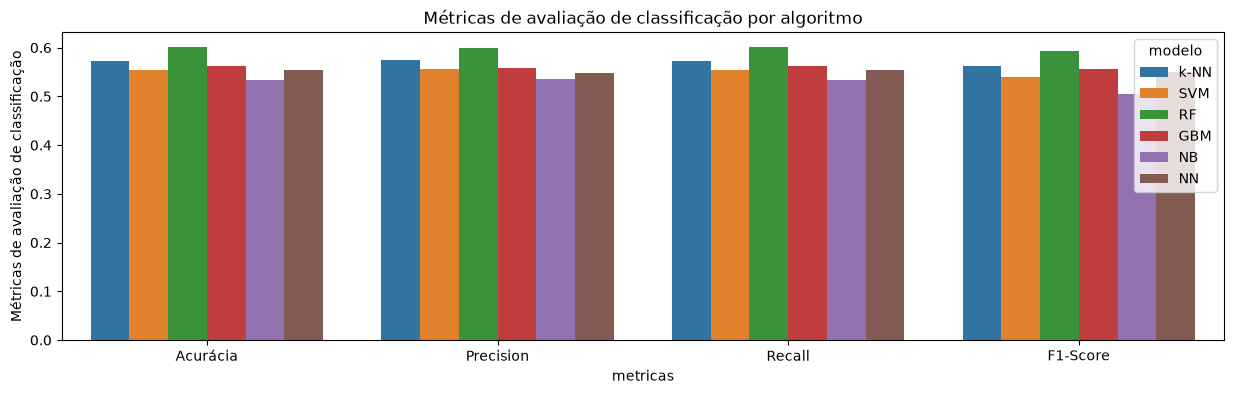

In [33]:
# Gráfico de barras das métricas de avaliação de classificação para os algoritmos
plt.figure(figsize=(15, 4))
plt.title("Métricas de avaliação de classificação por algoritmo")
p = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_test,
)
plt.ylabel("Métricas de avaliação de classificação")

plt.show()

In [34]:
df_test["k-NN"] = pred_knn.copy()
df_test["SVM"] = pred_svm.copy()
df_test["RF"] = pred_rf.copy()
df_test["GBM"] = pred_gbm.copy()
df_test["NB"] = pred_nb.copy()
df_test["NN"] = pred_nn.copy()
df_test.head()

,tipo_variante_frameshift,tipo_variante_missense,tipo_variante_nonsense,ancestralidade_AFR,ancestralidade_AMR,ancestralidade_Desconhecido,ancestralidade_EAS,ancestralidade_EUR,ancestralidade_SAS,gene_HTT,...,historico_familiar,gnomad_af_log,idade_inicio_sintomas,ataxia,k-NN,SVM,RF,GBM,NB,NN
0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.344445,37.9,2,2,2,0,0,2,0
1,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.609509,34.2,2,1,1,1,1,1,1
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.418307,59.3,1,1,1,1,1,1,1
3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.979071,50.2,2,2,1,2,1,2,2
4,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.688628,46.7,1,1,1,1,1,1,1


# Avalia Modelos

In [35]:
# Salvando os dataframes com as predições de cada modelo
os.makedirs(caminho_res, exist_ok=True)

dump(df_train, f"{caminho_res}df_train_resultados_classif")
dump(df_valid, f"{caminho_res}df_valid_resultados_classif")
dump(df_test, f"{caminho_res}df_test_resultados_classif")

df_train = load(f"{caminho_res}df_train_resultados_classif")
df_valid = load(f"{caminho_res}df_valid_resultados_classif")
df_test = load(f"{caminho_res}df_test_resultados_classif")

In [36]:
df_train.head()

,tipo_variante_frameshift,tipo_variante_missense,tipo_variante_nonsense,ancestralidade_AFR,ancestralidade_AMR,ancestralidade_Desconhecido,ancestralidade_EAS,ancestralidade_EUR,ancestralidade_SAS,gene_HTT,...,historico_familiar,gnomad_af_log,idade_inicio_sintomas,ataxia,k-NN,SVM,RF,GBM,NB,NN
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.346886,17.4,2,0,2,2,0,0,2
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.553847,36.0,1,2,2,2,2,1,2
2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,-0.275561,42.0,2,0,0,0,0,0,0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,-1.428356,24.8,2,0,0,0,0,0,0
4,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.685460,44.2,2,1,1,1,1,1,1


In [37]:
df_valid.head()

,tipo_variante_frameshift,tipo_variante_missense,tipo_variante_nonsense,ancestralidade_AFR,ancestralidade_AMR,ancestralidade_Desconhecido,ancestralidade_EAS,ancestralidade_EUR,ancestralidade_SAS,gene_HTT,...,historico_familiar,gnomad_af_log,idade_inicio_sintomas,ataxia,k-NN,SVM,RF,GBM,NB,NN
0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,-1.428356,61.2,1,1,1,2,2,2,2
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.635265,45.1,1,1,1,1,1,1,1
2,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.174626,69.5,1,1,1,1,1,1,1
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,1.555511,34.9,2,2,2,2,2,1,2
4,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.043893,56.9,2,1,2,2,2,1,2


In [38]:
df_test.head()

,tipo_variante_frameshift,tipo_variante_missense,tipo_variante_nonsense,ancestralidade_AFR,ancestralidade_AMR,ancestralidade_Desconhecido,ancestralidade_EAS,ancestralidade_EUR,ancestralidade_SAS,gene_HTT,...,historico_familiar,gnomad_af_log,idade_inicio_sintomas,ataxia,k-NN,SVM,RF,GBM,NB,NN
0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.344445,37.9,2,2,2,0,0,2,0
1,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.609509,34.2,2,1,1,1,1,1,1
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.418307,59.3,1,1,1,1,1,1,1
3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.979071,50.2,2,2,1,2,1,2,2
4,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.688628,46.7,1,1,1,1,1,1,1


In [39]:
len(df_test)

103

In [40]:
df_train["k-NN"].value_counts()

k-NN
1    293
0    263
2    159
Name: count, dtype: int64

In [41]:
df_valid["k-NN"].value_counts()

k-NN
1    85
0    75
2    45
Name: count, dtype: int64

In [42]:
df_test["k-NN"].value_counts()

k-NN
1    43
0    37
2    23
Name: count, dtype: int64

In [43]:
def testar_hipotese(df: pd.DataFrame) -> None:
    """
    Testa a hipótese de que a distribuição das classes no treino e no teste é estatisticamente igual (homogênea)
    ou diferente (heterogênea) usando o teste Qui-Quadrado.

    Parâmetros:
        df : pd.DataFrame
            DataFrame contendo as colunas 'Dataset' e 'Classe_Predita'.
        modelo : str
            Nome do modelo para exibição nos resultados.
    Retorna:
        None
    """
    # 3. Criando a Tabela de Contingência (Frequências Observadas)
    tabela_contingencia = pd.crosstab(df["Dataset"], df["Classe_Predita"])
    print("Tabela de Contingência (Observada):")
    print(tabela_contingencia)
    print("-" * 40)

    # 4. Realizando o Teste Qui-Quadrado
    chi2, p_valor, graus_liberdade, frequencias_esperadas = chi2_contingency(
        tabela_contingencia
    )

    # 5. Exibindo os resultados
    print(f"Estatística Qui-Quadrado: {chi2:.4f}")
    print(f"Graus de Liberdade: {graus_liberdade}")
    print(f"Valor-p: {p_valor:.4f}")

    # 6. Tomada de Decisão (usando nível de significância de 5%)
    alpha = 0.05
    print("\nConclusão:")
    if p_valor < alpha:
        print(
            "Rejeitamos H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE DIFERENTE (Heterogênea)."
        )
    else:
        print(
            "Falhamos em rejeitar H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE IGUAL (Homogênea)."
        )

    return None

In [44]:
modelo = "k-NN"
link = f"{caminho_res}df_classified_{modelo}"
dump(
    pd.DataFrame(
        {
            "Dataset": ["Treino"] * len(df_train) + ["Teste"] * len(df_test),
            "Classe_Predita": np.concatenate(
                [df_train[modelo].values, df_test[modelo].values]
            ),
        }
    ),
    link,
)
df_knn = load(link)
print(modelo)
display(df_knn.value_counts())
testar_hipotese(df_knn)

k-NN


Dataset  Classe_Predita
Treino   1                 293
         0                 263
         2                 159
Teste    1                  43
         0                  37
         2                  23
Name: count, dtype: int64

Tabela de Contingência (Observada):
Classe_Predita    0    1    2
Dataset                      
Teste            37   43   23
Treino          263  293  159
----------------------------------------
Estatística Qui-Quadrado: 0.0315
Graus de Liberdade: 2
Valor-p: 0.9844

Conclusão:
Falhamos em rejeitar H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE IGUAL (Homogênea).


In [45]:
modelo = "SVM"
link = f"{caminho_res}df_classified_{modelo}"
dump(
    pd.DataFrame(
        {
            "Dataset": ["Treino"] * len(df_train) + ["Teste"] * len(df_test),
            "Classe_Predita": np.concatenate(
                [df_train[modelo].values, df_test[modelo].values]
            ),
        }
    ),
    link,
)
df_svm = load(link)
print(modelo)
display(df_svm.value_counts())
testar_hipotese(df_svm)

SVM


Dataset  Classe_Predita
Treino   1                 294
         0                 251
         2                 170
Teste    1                  44
         0                  38
         2                  21
Name: count, dtype: int64

Tabela de Contingência (Observada):
Classe_Predita    0    1    2
Dataset                      
Teste            38   44   21
Treino          251  294  170
----------------------------------------
Estatística Qui-Quadrado: 0.5798
Graus de Liberdade: 2
Valor-p: 0.7483

Conclusão:
Falhamos em rejeitar H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE IGUAL (Homogênea).


In [46]:
modelo = "RF"
link = f"{caminho_res}df_classified_{modelo}"
dump(
    pd.DataFrame(
        {
            "Dataset": ["Treino"] * len(df_train) + ["Teste"] * len(df_test),
            "Classe_Predita": np.concatenate(
                [df_train[modelo].values, df_test[modelo].values]
            ),
        }
    ),
    link,
)
df_rf = load(link)
print(modelo)
display(df_rf.value_counts())
testar_hipotese(df_rf)

RF


Dataset  Classe_Predita
Treino   0                 273
         1                 232
         2                 210
Teste    0                  40
         1                  37
         2                  26
Name: count, dtype: int64

Tabela de Contingência (Observada):
Classe_Predita    0    1    2
Dataset                      
Teste            40   37   26
Treino          273  232  210
----------------------------------------
Estatística Qui-Quadrado: 0.8723
Graus de Liberdade: 2
Valor-p: 0.6465

Conclusão:
Falhamos em rejeitar H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE IGUAL (Homogênea).


In [47]:
modelo = "GBM"
link = f"{caminho_res}df_classified_{modelo}"
dump(
    pd.DataFrame(
        {
            "Dataset": ["Treino"] * len(df_train) + ["Teste"] * len(df_test),
            "Classe_Predita": np.concatenate(
                [df_train[modelo].values, df_test[modelo].values]
            ),
        }
    ),
    link,
)
df_gbm = load(link)
print(modelo)
display(df_gbm.value_counts())
testar_hipotese(df_gbm)

GBM


Dataset  Classe_Predita
Treino   0                 263
         1                 239
         2                 213
Teste    0                  39
         1                  37
         2                  27
Name: count, dtype: int64

Tabela de Contingência (Observada):
Classe_Predita    0    1    2
Dataset                      
Teste            39   37   27
Treino          263  239  213
----------------------------------------
Estatística Qui-Quadrado: 0.5872
Graus de Liberdade: 2
Valor-p: 0.7456

Conclusão:
Falhamos em rejeitar H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE IGUAL (Homogênea).


In [48]:
modelo = "NB"
link = f"{caminho_res}df_classified_{modelo}"
dump(
    pd.DataFrame(
        {
            "Dataset": ["Treino"] * len(df_train) + ["Teste"] * len(df_test),
            "Classe_Predita": np.concatenate(
                [df_train[modelo].values, df_test[modelo].values]
            ),
        }
    ),
    link,
)
df_nb = load(link)
print(modelo)
display(df_nb.value_counts())
testar_hipotese(df_nb)

NB


Dataset  Classe_Predita
Treino   1                 312
         0                 275
         2                 128
Teste    1                  47
         0                  41
         2                  15
Name: count, dtype: int64

Tabela de Contingência (Observada):
Classe_Predita    0    1    2
Dataset                      
Teste            41   47   15
Treino          275  312  128
----------------------------------------
Estatística Qui-Quadrado: 0.6979
Graus de Liberdade: 2
Valor-p: 0.7054

Conclusão:
Falhamos em rejeitar H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE IGUAL (Homogênea).


In [49]:
modelo = "NN"
link = f"{caminho_res}df_classified_{modelo}"
dump(
    pd.DataFrame(
        {
            "Dataset": ["Treino"] * len(df_train) + ["Teste"] * len(df_test),
            "Classe_Predita": np.concatenate(
                [df_train[modelo].values, df_test[modelo].values]
            ),
        }
    ),
    link,
)
df_nn = load(link)
print(modelo)
display(df_nn.value_counts())
testar_hipotese(df_nn)

NN


Dataset  Classe_Predita
Treino   2                 256
         0                 246
         1                 213
Teste    0                  35
         1                  35
         2                  33
Name: count, dtype: int64

Tabela de Contingência (Observada):
Classe_Predita    0    1    2
Dataset                      
Teste            35   35   33
Treino          246  213  256
----------------------------------------
Estatística Qui-Quadrado: 0.8875
Graus de Liberdade: 2
Valor-p: 0.6416

Conclusão:
Falhamos em rejeitar H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE IGUAL (Homogênea).
